# Group 2 — E. coli Comparative Genomics

## Data Transformation and Data Mining

**Bioinformatics Research Project**

### Research Topic

**Investigating the Evolution and Distribution of Antibiotic Resistance Among Selected *Escherichia coli* Strains Using Comparative Genomics**

### Group Members ICS 4D

| Student Number | Student Name |
|---|---|
| 160588 | Kirui Sharlet Jerono |
| 166531 | Deborah Kaburu |
| 166488 | Bwibo Ethan Nimrod |
| 166386 | Githinji Nathan Rugo |
| 162831 | Wangeci Brown Kamau |
| 165852 | Njenga Martin Njuguna |

### Objective

This notebook documents the data transformation and data mining stages of the Knowledge Discovery in Databases (KDD) process.

Building on the previously prepared dataset of nine *E. coli* genome assemblies, the analysis aims to identify antibiotic resistance-associated genes, compare their distribution across strains, and explore patterns of genomic similarity.

The analysis will include data transformation, resistance-gene identification, evaluation of results, comparative analysis, and visualisation of observed patterns.

### Data Source

**National Center for Biotechnology Information (NCBI) RefSeq Genome Database**

https://www.ncbi.nlm.nih.gov/datasets/genome/

**Biological Data Type:** Genomic DNA sequences in FASTA format, accompanied by assembly metadata.

**Dataset:** Nine *E. coli* genome assemblies containing 15 DNA sequence records.

In [1]:

# STAGE 4 — DATA TRANSFORMATION
# Step 1: Install and verify Python dependencies

!pip -q install biopython pandas numpy matplotlib seaborn scipy

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import Bio

print("=== ENVIRONMENT SETUP ===")
print("Biopython:", Bio.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

print("\nPython environment ready.")


=== ENVIRONMENT SETUP ===
Biopython: 1.88
Pandas: 2.2.3
NumPy: 2.4.6
SciPy: 1.16.3

Python environment ready.


In [2]:

# Step 2: Define the verified NCBI RefSeq assemblies

genome_accessions = {
    "GCF_000005845.2": "MG1655",
    "GCF_000006665.1": "EDL933",
    "GCF_000007445.1": "CFT073",
    "GCF_000008865.2": "Sakai",
    "GCF_000010245.2": "W3110",
    "GCF_000013265.1": "UTI89",
    "GCF_000013305.1": "536",
    "GCF_000014845.1": "APEC O1",
    "GCF_000017765.1": "HS"
}

print("=== SELECTED E. COLI GENOMES ===")

for accession, strain in genome_accessions.items():
    print(f"{accession} — {strain}")

print("\nTotal assemblies:", len(genome_accessions))


=== SELECTED E. COLI GENOMES ===
GCF_000005845.2 — MG1655
GCF_000006665.1 — EDL933
GCF_000007445.1 — CFT073
GCF_000008865.2 — Sakai
GCF_000010245.2 — W3110
GCF_000013265.1 — UTI89
GCF_000013305.1 — 536
GCF_000014845.1 — APEC O1
GCF_000017765.1 — HS

Total assemblies: 9


In [3]:

# STEP 3: Download the nine E. coli genome assemblies

import os
import subprocess
import zipfile
from pathlib import Path

# Create a directory for the genomic data
data_dir = Path("/content/ecoli_kdd_data")
data_dir.mkdir(parents=True, exist_ok=True)

# Install the NCBI Datasets command-line tool
subprocess.run(
    [
        "curl", "-L", "--fail", "--silent", "--show-error",
        "https://ftp.ncbi.nlm.nih.gov/pub/datasets/command-line/v2/linux-amd64/datasets",
        "-o", "/usr/local/bin/datasets"
    ],
    check=True
)

subprocess.run(
    ["chmod", "+x", "/usr/local/bin/datasets"],
    check=True
)

# Check installation
subprocess.run(
    ["datasets", "version"],
    check=True
)

# Save the nine verified accessions
accession_file = data_dir / "accessions.txt"

with open(accession_file, "w") as file:
    for accession in genome_accessions:
        file.write(accession + "\n")

# Download genomic sequences
zip_path = data_dir / "ecoli_genomes.zip"

subprocess.run(
    [
        "datasets", "download", "genome", "accession",
        "--inputfile", str(accession_file),
        "--include", "genome",
        "--filename", str(zip_path)
    ],
    check=True
)

# Extract downloaded files
extract_dir = data_dir / "genomes"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("\n=== GENOME DOWNLOAD COMPLETE ===")
print("Download location:", extract_dir)



=== GENOME DOWNLOAD COMPLETE ===
Download location: /content/ecoli_kdd_data/genomes


In [4]:

# STEP 4: Verify downloaded genome FASTA files

from Bio import SeqIO
import pandas as pd

# Find all downloaded FASTA files
fasta_files = sorted(extract_dir.rglob("*.fna"))

verification_records = []

for fasta_path in fasta_files:

    accession = fasta_path.parent.name

    if accession not in genome_accessions:
        continue

    records = list(SeqIO.parse(str(fasta_path), "fasta"))

    verification_records.append({
        "assembly_accession": accession,
        "strain": genome_accessions[accession],
        "sequence_count": len(records),
        "total_length_bp": sum(len(record.seq) for record in records)
    })

verification_df = pd.DataFrame(verification_records)

print("=== GENOME VERIFICATION RESULTS ===")

display(verification_df)

print("\nExpected assemblies:", len(genome_accessions))
print("Downloaded assemblies:", len(verification_df))

print(
    "Total DNA sequence records:",
    verification_df["sequence_count"].sum()
)

# Check whether any requested assemblies are missing
downloaded_accessions = set(
    verification_df["assembly_accession"]
)

missing_accessions = (
    set(genome_accessions) - downloaded_accessions
)

print("\nMissing assemblies:", sorted(missing_accessions))

# Validate assembly uniqueness
print(
    "Duplicate assembly accessions:",
    verification_df["assembly_accession"].duplicated().sum()
)


=== GENOME VERIFICATION RESULTS ===


,assembly_accession,strain,sequence_count,total_length_bp
0,GCF_000005845.2,MG1655,1,4641652
1,GCF_000006665.1,EDL933,2,5620522
2,GCF_000007445.1,CFT073,1,5231428
3,GCF_000008865.2,Sakai,3,5594605
4,GCF_000010245.2,W3110,1,4646332
5,GCF_000013265.1,UTI89,2,5179971
6,GCF_000013305.1,536,1,4938920
7,GCF_000014845.1,APEC O1,3,5497653
8,GCF_000017765.1,HS,1,4643538



Expected assemblies: 9
Downloaded assemblies: 9
Total DNA sequence records: 15

Missing assemblies: []
Duplicate assembly accessions: 0


In [5]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=verification_df)

https://docs.google.com/spreadsheets/d/1NlM76z58SB2iGYCygILXyVIMO-orLVgTrTlUhvldmjo/edit#gid=0


### 4.1 Retrieval and Verification of Genomic Data

The nine previously selected *Escherichia coli* RefSeq genome assemblies were retrieved from NCBI in FASTA format.

The genomic sequences were inspected using Biopython to verify assembly accessions, sequence-record counts and total assembled DNA lengths.

This verification ensures that the same genomic dataset used during the earlier data preparation stage is available for subsequent transformation and antibiotic resistance gene analysis.

### 4.2 Genomic Sequence Transformation

The verified genomic sequences were prepared for subsequent antibiotic resistance gene analysis.

The transformation involved standardising sequence identifiers, converting nucleotide characters to uppercase and organising sequences into separate FASTA files for each genome assembly.

These transformations were necessary to ensure consistent sequence representation, maintain traceability between genomic records and their source assemblies, and provide suitable inputs for downstream bioinformatics tools.

Ambiguous nucleotide symbols were retained to preserve the original sequence lengths and genomic positions.

In [6]:

# STEP 5: Transform genomic FASTA files
# Stage 4 — Data Transformation

from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from pathlib import Path
import pandas as pd

# Create output folder
transformed_dir = Path(
    "/content/ecoli_kdd_data/transformed_genomes"
)

transformed_dir.mkdir(
    parents=True,
    exist_ok=True
)

transformation_results = []

# Process each verified genome assembly
for fasta_path in fasta_files:

    accession = fasta_path.parent.name

    if accession not in genome_accessions:
        continue

    transformed_records = []

    for index, record in enumerate(
        SeqIO.parse(str(fasta_path), "fasta"),
        start=1
    ):

        # Convert sequence to uppercase
        dna_sequence = str(record.seq).upper()

        # Create a unique, traceable identifier
        new_id = f"{accession}_seq{index}"

        transformed_record = SeqRecord(
            Seq(dna_sequence),
            id=new_id,
            description=""
        )

        transformed_records.append(
            transformed_record
        )

    # Save one FASTA file per assembly
    output_path = (
        transformed_dir / f"{accession}.fna"
    )

    SeqIO.write(
        transformed_records,
        str(output_path),
        "fasta"
    )

    transformation_results.append({
        "assembly_accession": accession,
        "strain": genome_accessions[accession],
        "sequence_count": len(transformed_records),
        "total_length_bp": sum(
            len(record.seq)
            for record in transformed_records
        ),
        "output_file": output_path.name
    })

# Display transformation summary
transformation_df = pd.DataFrame(
    transformation_results
)

print("=== GENOMIC DATA TRANSFORMATION ===")

display(transformation_df)

print(
    "\nTotal transformed assemblies:",
    len(transformation_df)
)

print(
    "Total transformed DNA records:",
    transformation_df["sequence_count"].sum()
)

print(
    "\nOutput directory:",
    transformed_dir
)


=== GENOMIC DATA TRANSFORMATION ===


,assembly_accession,strain,sequence_count,total_length_bp,output_file
0,GCF_000005845.2,MG1655,1,4641652,GCF_000005845.2.fna
1,GCF_000006665.1,EDL933,2,5620522,GCF_000006665.1.fna
2,GCF_000007445.1,CFT073,1,5231428,GCF_000007445.1.fna
3,GCF_000008865.2,Sakai,3,5594605,GCF_000008865.2.fna
4,GCF_000010245.2,W3110,1,4646332,GCF_000010245.2.fna
5,GCF_000013265.1,UTI89,2,5179971,GCF_000013265.1.fna
6,GCF_000013305.1,536,1,4938920,GCF_000013305.1.fna
7,GCF_000014845.1,APEC O1,3,5497653,GCF_000014845.1.fna
8,GCF_000017765.1,HS,1,4643538,GCF_000017765.1.fna



Total transformed assemblies: 9
Total transformed DNA records: 15

Output directory: /content/ecoli_kdd_data/transformed_genomes


In [7]:

# STEP 6: Validate transformed FASTA sequences

validation_results = []

for fasta_path in fasta_files:

    accession = fasta_path.parent.name

    if accession not in genome_accessions:
        continue

    original_records = list(
        SeqIO.parse(str(fasta_path), "fasta")
    )

    transformed_path = (
        transformed_dir / f"{accession}.fna"
    )

    transformed_records = list(
        SeqIO.parse(str(transformed_path), "fasta")
    )

    # Compare sequences after standardising case
    sequences_match = (
        len(original_records) == len(transformed_records)
        and all(
            str(original.seq).upper()
            == str(transformed.seq)
            for original, transformed in zip(
                original_records,
                transformed_records
            )
        )
    )

    validation_results.append({
        "assembly_accession": accession,
        "original_records": len(original_records),
        "transformed_records": len(transformed_records),
        "sequences_match": sequences_match
    })

transformation_validation_df = pd.DataFrame(
    validation_results
)

print("=== TRANSFORMATION VALIDATION ===")

display(transformation_validation_df)

print(
    "\nAssemblies with matching sequences:",
    transformation_validation_df[
        "sequences_match"
    ].sum()
)

print(
    "All transformations validated:",
    transformation_validation_df[
        "sequences_match"
    ].all()
)


=== TRANSFORMATION VALIDATION ===


,assembly_accession,original_records,transformed_records,sequences_match
0,GCF_000005845.2,1,1,True
1,GCF_000006665.1,2,2,True
2,GCF_000007445.1,1,1,True
3,GCF_000008865.2,3,3,True
4,GCF_000010245.2,1,1,True
5,GCF_000013265.1,2,2,True
6,GCF_000013305.1,1,1,True
7,GCF_000014845.1,3,3,True
8,GCF_000017765.1,1,1,True



Assemblies with matching sequences: 9
All transformations validated: True


## 2. Data Mining

### 2.1 Selection of Analysis Technique

**Selected Technique: Reference-Based Antimicrobial Resistance Gene Detection Using AMRFinderPlus**

AMRFinderPlus was selected to identify antimicrobial resistance-associated genes within the nine *Escherichia coli* genome assemblies.

The technique compares genomic sequences and predicted protein sequences against curated reference databases to identify known resistance-associated genes and relevant genetic variants.

This approach is appropriate because the research dataset consists of genomic DNA sequences rather than labelled resistance phenotypes. It enables the identification and comparison of resistance-associated genetic features without requiring a supervised machine learning model.

The expected outputs include detected resistance-associated genes, their classifications, sequence identity measurements and their distribution across the selected strains.

These results will support subsequent comparative analysis of resistance-gene profiles. However, the presence of a resistance-associated gene does not independently confirm phenotypic antibiotic resistance, and gene-profile similarity alone does not establish evolutionary relatedness.

In [8]:

# STEP 7: Install AMRFinderPlus
# Section 2.2 — Perform the Analysis

import subprocess
import shutil

print("=== AMRFINDERPLUS INSTALLATION ===")

# Install Conda-compatible package manager
subprocess.run(
    [
        "bash", "-c",
        'curl -Ls https://micro.mamba.pm/install.sh | bash'
    ],
    check=True
)

print("\nInstallation script completed.")
print("Checking whether micromamba is available...")

# Locate micromamba
possible_paths = [
    "/root/.local/bin/micromamba",
    "/usr/local/bin/micromamba"
]

micromamba_path = next(
    (path for path in possible_paths if shutil.which(path) or __import__("os").path.exists(path)),
    None
)

print("Micromamba path:", micromamba_path)


=== AMRFINDERPLUS INSTALLATION ===

Installation script completed.
Checking whether micromamba is available...
Micromamba path: /root/.local/bin/micromamba


In [9]:

# STEP 8: Install AMRFinderPlus
# Section 2.2 — Perform the Analysis

import subprocess
from pathlib import Path

micromamba = "/root/.local/bin/micromamba"

print("=== INSTALLING AMRFINDERPLUS ===")

# Create a dedicated environment with AMRFinderPlus
result = subprocess.run(
    [
        micromamba,
        "create",
        "-y",
        "-n", "amr_env",
        "-c", "conda-forge",
        "-c", "bioconda",
        "--strict-channel-priority",
        "ncbi-amrfinderplus"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-3000:])
print(result.stderr[-3000:])

if result.returncode != 0:
    raise RuntimeError(
        "AMRFinderPlus installation failed. "
        "Review the output above."
    )

# Locate the executable inside the environment
amrfinder_executable = (
    Path("/root/micromamba/envs/amr_env/bin/amrfinder")
)

# Find executable if the environment uses another root
if not amrfinder_executable.exists():
    search_result = subprocess.run(
        [
            micromamba, "run", "-n", "amr_env",
            "which", "amrfinder"
        ],
        capture_output=True,
        text=True
    )

    if search_result.returncode == 0:
        amrfinder_executable = Path(
            search_result.stdout.strip()
        )

print("\n=== INSTALLATION VERIFICATION ===")

version_result = subprocess.run(
    [
        micromamba, "run", "-n", "amr_env",
        "amrfinder", "--version"
    ],
    capture_output=True,
    text=True
)

print("Version:", version_result.stdout.strip())
print("Additional output:", version_result.stderr.strip())

if version_result.returncode != 0:
    raise RuntimeError(
        "AMRFinderPlus could not be executed."
    )

print("\nAMRFinderPlus installed successfully.")


=== INSTALLING AMRFINDERPLUS ===
Return code: 0
g libstdcxx-16.2.0-h934c35e_7
Linking libedit-3.1.20260512-pl5321h373387f_0
Linking libgfortran-16.2.0-h69a702a_7
Linking pcre2-10.47-h8b3dc9c_1
Linking perl-5.32.1-10_h7cc23a3_perl5
Linking libunistring-0.9.10-h7f98852_0
Linking libstdcxx-ng-16.2.0-hdf11a46_7
Linking libgfortran-ng-16.2.0-h69a702a_7
Linking libopenblas-0.3.34-pthreads_hf13c14d_2
Linking perl-storable-3.15-pl5321hb9d3cd8_2
Linking perl-scalar-list-utils-1.70-pl5321hb03c661_0
Linking perl-compress-raw-zlib-2.214-pl5321h4dac143_0
Linking perl-compress-raw-bzip2-2.214-pl5321hda65f42_0
Linking libidn2-2.3.8-h9866765_3
Linking icu-75.1-he02047a_0
Linking openmpi-4.1.6-hc5af2df_101
 
For Linux 64, Open MPI is built with CUDA awareness but this support is disabled by default.
To enable it, please set the environment variable OMPI_MCA_opal_cuda_support=true before
launching your MPI processes. Equivalently, you can set the MCA parameter in the command line:
mpiexec --mca opal_cud

In [10]:

# STEP 9: Download the AMRFinderPlus reference database
# Section 2.2 — Perform the Analysis

import subprocess
from pathlib import Path

micromamba = "/root/.local/bin/micromamba"

print("=== DOWNLOADING AMRFINDERPLUS DATABASE ===")

# Download and initialise the reference database
result = subprocess.run(
    [
        micromamba, "run", "-n", "amr_env",
        "amrfinder", "-u"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)

print("\n=== STANDARD OUTPUT ===")
print(result.stdout[-4000:])

print("\n=== ADDITIONAL OUTPUT ===")
print(result.stderr[-4000:])

if result.returncode != 0:
    raise RuntimeError(
        "Database download or update failed. "
        "Check the messages above."
    )

print("\nAMRFinderPlus database update completed.")


=== DOWNLOADING AMRFINDERPLUS DATABASE ===
Return code: 0

=== STANDARD OUTPUT ===


=== ADDITIONAL OUTPUT ===
Running: amrfinder -u
The number of threads cannot be greater than 2 on this computer
The current number of threads is 4, reducing to 2
Software directory: /root/micromamba/envs/amr_env/bin/
Software version: 4.2.7
Running: /root/micromamba/envs/amr_env/bin/amrfinder_update -d /root/micromamba/envs/amr_env/share/amrfinderplus/data
Looking up the published databases at https://ftp.ncbi.nlm.nih.gov/pathogen/Antimicrobial_resistance/AMRFinderPlus/database/
Looking for the target directory: /root/micromamba/envs/amr_env/share/amrfinderplus/data/2026-10-29.1/
Running: /root/micromamba/envs/amr_env/bin/amrfinder_index /root/micromamba/envs/amr_env/share/amrfinderplus/data/2026-10-29.1/
Indexing
amrfinder_index took 2 seconds to complete
amrfinder_update took 11 seconds to complete
Database directory: /root/micromamba/envs/amr_env/share/amrfinderplus/data/2026-10-29.1
Database versio

In [11]:

# STEP 10: Verify AMRFinderPlus configuration

import subprocess

print("=== AMRFINDERPLUS CONFIGURATION ===")

result = subprocess.run(
    [
        micromamba, "run", "-n", "amr_env",
        "amrfinder", "--database_version"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Database version:", result.stdout.strip())
print("Additional output:", result.stderr.strip())

if result.returncode != 0:
    raise RuntimeError(
        "Could not verify the AMRFinderPlus database."
    )

print("\nDatabase verification successful.")


=== AMRFINDERPLUS CONFIGURATION ===
Return code: 0
Database version: Software directory: '/root/micromamba/envs/amr_env/bin/'
Software version: 4.2.7
Database directory: '/root/micromamba/envs/amr_env/share/amrfinderplus/data/2026-10-29.1'
Database version: 2026-10-29.1
Additional output: Running: amrfinder --database_version
The number of threads cannot be greater than 2 on this computer
The current number of threads is 4, reducing to 2
amrfinder took 0 seconds to complete

Database verification successful.


### 2.2.1 Identification of Antimicrobial Resistance-Associated Genes

AMRFinderPlus version 4.2.7 was used with reference database version 2026-10-29.1 to screen the nine *Escherichia coli* genome assemblies for antimicrobial resistance-associated genes.

Each transformed genome assembly was analysed separately using its nucleotide FASTA sequence.

The analysis was designed to identify resistance-associated genetic features and generate structured outputs containing gene names, resistance classifications, sequence identity measurements and genomic locations where available.

The resulting annotations will be used to compare resistance-gene distributions across strains. Because this initial analysis uses nucleotide sequences alone, its findings will be interpreted as a genomic screening result rather than a complete prediction of phenotypic antibiotic susceptibility.

In [12]:

# STEP 11: Detect antimicrobial resistance-associated genes
# Section 2.2 — Perform the Analysis

import subprocess
from pathlib import Path
import pandas as pd

micromamba = "/root/.local/bin/micromamba"

results_dir = Path(
    "/content/ecoli_kdd_data/amr_results"
)
results_dir.mkdir(parents=True, exist_ok=True)

analysis_status = []

print("=== AMRFINDERPLUS ANALYSIS ===")

for accession, strain in genome_accessions.items():

    input_fasta = transformed_dir / f"{accession}.fna"
    output_file = results_dir / f"{accession}_amr.tsv"

    if not input_fasta.exists():
        raise FileNotFoundError(
            f"Missing FASTA file: {input_fasta}"
        )

    print(f"\nAnalysing {strain} ({accession})...")

    command = [
        micromamba,
        "run", "-n", "amr_env",
        "amrfinder",
        "-n", str(input_fasta),
        "--threads", "2",
        "-o", str(output_file)
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    analysis_status.append({
        "assembly_accession": accession,
        "strain": strain,
        "return_code": result.returncode,
        "output_exists": output_file.exists()
    })

    if result.returncode != 0:
        print("ERROR:")
        print(result.stderr[-2000:])
    else:
        print("Completed successfully.")

status_df = pd.DataFrame(analysis_status)

print("\n=== ANALYSIS STATUS ===")
display(status_df)

if not (status_df["return_code"] == 0).all():
    raise RuntimeError(
        "One or more AMRFinderPlus analyses failed."
    )

print("\nAll nine genome analyses completed.")


=== AMRFINDERPLUS ANALYSIS ===

Analysing MG1655 (GCF_000005845.2)...
Completed successfully.

Analysing EDL933 (GCF_000006665.1)...
Completed successfully.

Analysing CFT073 (GCF_000007445.1)...
Completed successfully.

Analysing Sakai (GCF_000008865.2)...
Completed successfully.

Analysing W3110 (GCF_000010245.2)...
Completed successfully.

Analysing UTI89 (GCF_000013265.1)...
Completed successfully.

Analysing 536 (GCF_000013305.1)...
Completed successfully.

Analysing APEC O1 (GCF_000014845.1)...
Completed successfully.

Analysing HS (GCF_000017765.1)...
Completed successfully.

=== ANALYSIS STATUS ===


,assembly_accession,strain,return_code,output_exists
0,GCF_000005845.2,MG1655,0,True
1,GCF_000006665.1,EDL933,0,True
2,GCF_000007445.1,CFT073,0,True
3,GCF_000008865.2,Sakai,0,True
4,GCF_000010245.2,W3110,0,True
5,GCF_000013265.1,UTI89,0,True
6,GCF_000013305.1,536,0,True
7,GCF_000014845.1,APEC O1,0,True
8,GCF_000017765.1,HS,0,True



All nine genome analyses completed.


In [13]:

# STEP 12: Combine AMRFinderPlus results

import pandas as pd

combined_results = []

for accession, strain in genome_accessions.items():

    output_file = (
        results_dir / f"{accession}_amr.tsv"
    )

    if not output_file.exists():
        raise FileNotFoundError(
            f"Missing analysis output: {output_file}"
        )

    df = pd.read_csv(
        output_file,
        sep="\t"
    )

    df.insert(0, "strain", strain)
    df.insert(0, "assembly_accession", accession)

    combined_results.append(df)

amr_df = pd.concat(
    combined_results,
    ignore_index=True
)

print("=== COMBINED AMR RESULTS ===")

print("Total detected records:", len(amr_df))

print("\nAvailable columns:")
print(amr_df.columns.tolist())

print("\nFirst 10 detected records:")
display(amr_df.head(10))

# Save combined results
combined_output = (
    results_dir / "combined_amr_results.csv"
)

amr_df.to_csv(
    combined_output,
    index=False
)

print("\nCombined results saved to:", combined_output)


=== COMBINED AMR RESULTS ===
Total detected records: 5

Available columns:
['assembly_accession', 'strain', 'Protein id', 'Contig id', 'Start', 'Stop', 'Strand', 'Element symbol', 'Element name', 'Scope', 'Type', 'Subtype', 'Class', 'Subclass', 'Method', 'Target length', 'Reference sequence length', '% Coverage of reference', '% Identity to reference', 'Alignment length', 'Closest reference accession', 'Closest reference name', 'HMM accession', 'HMM description']

First 10 detected records:


/tmp/ipykernel_1373/3995992856.py:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  amr_df = pd.concat(


,assembly_accession,strain,Protein id,Contig id,Start,Stop,Strand,Element symbol,Element name,Scope,...,Method,Target length,Reference sequence length,% Coverage of reference,% Identity to reference,Alignment length,Closest reference accession,Closest reference name,HMM accession,HMM description
0,GCF_000014845.1,APEC O1,NaN,GCF_000014845.1_seq3,89606,90793,-,tet(C),tetracycline efflux MFS transporter Tet(C),core,...,EXACTX,396,396,100.0,100.0,396,WP_000841446.1,tetracycline efflux MFS transporter Tet(C),NaN,NaN
1,GCF_000014845.1,APEC O1,NaN,GCF_000014845.1_seq3,96620,97408,+,aadA1,ANT(3'')-Ia family aminoglycoside nucleotidylt...,core,...,EXACTX,263,263,100.0,100.0,263,WP_001206316.1,ANT(3'')-Ia family aminoglycoside nucleotidylt...,NaN,NaN
2,GCF_000014845.1,APEC O1,NaN,GCF_000014845.1_seq3,97578,98474,+,aac(3)-VIa,aminoglycoside N-acetyltransferase AAC(3)-VIa,core,...,EXACTX,299,299,100.0,100.0,299,WP_000131886.1,aminoglycoside N-acetyltransferase AAC(3)-VIa,NaN,NaN
3,GCF_000014845.1,APEC O1,NaN,GCF_000014845.1_seq3,104136,104480,+,qacEdelta1,quaternary ammonium compound efflux SMR transp...,core,...,ALLELEX,115,115,100.0,100.0,115,WP_000679427.1,quaternary ammonium compound efflux SMR transp...,NaN,NaN
4,GCF_000014845.1,APEC O1,NaN,GCF_000014845.1_seq3,104477,105313,+,sul1,sulfonamide-resistant dihydropteroate synthase...,core,...,EXACTX,279,279,100.0,100.0,279,WP_000259031.1,sulfonamide-resistant dihydropteroate synthase...,NaN,NaN



Combined results saved to: /content/ecoli_kdd_data/amr_results/combined_amr_results.csv


### 2.2.2 Distribution of Detected Resistance-Associated Elements

The initial nucleotide-based AMRFinderPlus screening identified five resistance-associated genetic elements across the nine *E. coli* genome assemblies.

All five elements were detected in the APEC O1 assembly, while no elements were reported for the remaining eight assemblies under the selected screening settings.

The detected elements included genes associated with tetracycline resistance, aminoglycoside resistance, sulfonamide resistance and quaternary ammonium compound efflux.

These findings indicate variation in the detected resistance-associated gene profiles among the selected genomes. However, the absence of detected elements does not necessarily indicate phenotypic susceptibility, since additional resistance mechanisms may not be captured by nucleotide-only screening.

In [14]:

# STEP 13: Summarise detected AMR-associated elements

import pandas as pd

# Count detected elements per strain
gene_counts = (
    amr_df.groupby("strain")
    .size()
    .to_dict()
)

summary_records = []

for accession, strain in genome_accessions.items():

    strain_data = amr_df[
        amr_df["assembly_accession"] == accession
    ]

    detected_genes = sorted(
        strain_data["Element symbol"]
        .dropna()
        .unique()
        .tolist()
    )

    summary_records.append({
        "assembly_accession": accession,
        "strain": strain,
        "detected_elements": len(strain_data),
        "unique_elements": len(detected_genes),
        "element_names": (
            ", ".join(detected_genes)
            if detected_genes
            else "None detected"
        )
    })

amr_summary_df = pd.DataFrame(summary_records)

print("=== AMR DISTRIBUTION SUMMARY ===")
display(amr_summary_df)

print(
    "\nGenomes with detected elements:",
    (amr_summary_df["detected_elements"] > 0).sum()
)

print(
    "Genomes without detected elements:",
    (amr_summary_df["detected_elements"] == 0).sum()
)

print(
    "Total detected elements:",
    amr_summary_df["detected_elements"].sum()
)

# Save summary
amr_summary_df.to_csv(
    results_dir / "amr_distribution_summary.csv",
    index=False
)


=== AMR DISTRIBUTION SUMMARY ===


,assembly_accession,strain,detected_elements,unique_elements,element_names
0,GCF_000005845.2,MG1655,0,0,None detected
1,GCF_000006665.1,EDL933,0,0,None detected
2,GCF_000007445.1,CFT073,0,0,None detected
3,GCF_000008865.2,Sakai,0,0,None detected
4,GCF_000010245.2,W3110,0,0,None detected
5,GCF_000013265.1,UTI89,0,0,None detected
6,GCF_000013305.1,536,0,0,None detected
7,GCF_000014845.1,APEC O1,5,5,"aac(3)-VIa, aadA1, qacEdelta1, sul1, tet(C)"
8,GCF_000017765.1,HS,0,0,None detected



Genomes with detected elements: 1
Genomes without detected elements: 8
Total detected elements: 5


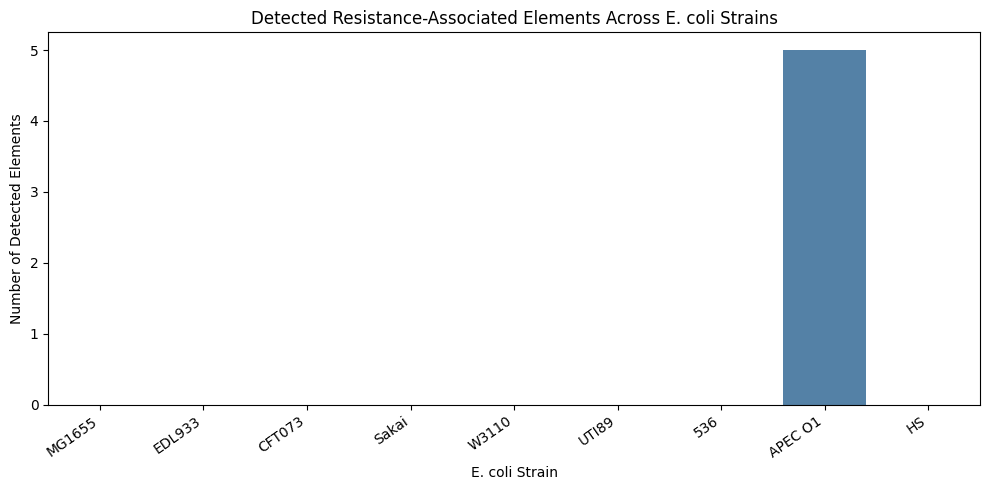

In [15]:

# STEP 14: Visualise AMR-associated element counts

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=amr_summary_df,
    x="strain",
    y="detected_elements",
    color="steelblue"
)

plt.title(
    "Detected Resistance-Associated Elements Across E. coli Strains"
)

plt.xlabel("E. coli Strain")
plt.ylabel("Number of Detected Elements")

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    results_dir / "amr_element_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation of Resistance-Associated Element Distribution

The AMRFinderPlus analysis identified five resistance-associated genetic elements across the nine selected *Escherichia coli* genome assemblies.

All five elements were detected in the APEC O1 strain, while the remaining eight strains had no reported detections under the nucleotide-based screening settings.

The detected elements were associated with tetracycline resistance, aminoglycoside resistance, sulfonamide resistance, and quaternary ammonium compound efflux.

This distribution demonstrates differences in the detected resistance-associated genetic profiles among the selected strains. APEC O1 exhibited a distinct profile containing multiple resistance-associated elements.

However, the absence of reported elements in the remaining strains does not establish antibiotic susceptibility, as other resistance mechanisms, including certain chromosomal mutations, may not have been identified by the initial screening method.

### 2.2.3 Transformation of Genomic Sequences into k-mer Features

To complement the resistance-gene detection analysis, the genomic DNA sequences were selected for transformation into k-mer frequency profiles.

A k-mer is a nucleotide subsequence of a specified length. In this analysis, k = 5 was selected, producing 1,024 possible combinations of the standard DNA bases A, T, G and C.

For each genome, the frequency of each five-base sequence will be calculated and normalised by the total number of valid k-mers.

This transformation converts genomic sequences of different lengths into numerical feature vectors of equal dimensions, allowing quantitative comparison between strains.

K-mers containing ambiguous nucleotide symbols will be excluded from frequency calculations without altering the original FASTA sequences.

The resulting profiles will support exploratory analysis of genomic composition and similarity. They will not be treated as direct measurements of antibiotic resistance or definitive evolutionary relationships.

In [16]:

# STEP 15: Transform genome sequences into 5-mer profiles

from Bio import SeqIO
from collections import Counter
from itertools import product
import pandas as pd
import numpy as np

k = 5

# Generate all possible 5-mers
all_kmers = [
    "".join(p)
    for p in product("ATGC", repeat=k)
]

kmer_results = []

print("=== GENOMIC K-MER TRANSFORMATION ===")

for accession, strain in genome_accessions.items():

    fasta_path = transformed_dir / f"{accession}.fna"

    kmer_counts = Counter()
    valid_kmers = 0

    for record in SeqIO.parse(str(fasta_path), "fasta"):

        sequence = str(record.seq).upper()

        for i in range(len(sequence) - k + 1):

            kmer = sequence[i:i+k]

            if set(kmer).issubset({"A", "T", "G", "C"}):
                kmer_counts[kmer] += 1
                valid_kmers += 1

    if valid_kmers == 0:
        raise ValueError(
            f"No valid k-mers found for {strain}"
        )

    # Normalise frequencies
    frequencies = {
        mer: kmer_counts[mer] / valid_kmers
        for mer in all_kmers
    }

    row = {
        "assembly_accession": accession,
        "strain": strain,
        "valid_kmers": valid_kmers,
        **frequencies
    }

    kmer_results.append(row)

    print(
        f"{strain}: {valid_kmers:,} valid 5-mers"
    )

kmer_df = pd.DataFrame(kmer_results)

print("\n=== K-MER FEATURE MATRIX ===")
print("Genomes:", len(kmer_df))
print("K-mer features:", len(all_kmers))

display(kmer_df.iloc[:, :10])

# Save transformed features
kmer_df.to_csv(
    results_dir / "ecoli_5mer_features.csv",
    index=False
)

print("\nK-mer transformation completed.")


=== GENOMIC K-MER TRANSFORMATION ===
MG1655: 4,641,648 valid 5-mers
EDL933: 5,604,513 valid 5-mers
CFT073: 5,230,110 valid 5-mers
Sakai: 5,594,593 valid 5-mers
W3110: 4,646,328 valid 5-mers
UTI89: 5,179,963 valid 5-mers
536: 4,938,916 valid 5-mers
APEC O1: 5,497,178 valid 5-mers
HS: 4,643,529 valid 5-mers

=== K-MER FEATURE MATRIX ===
Genomes: 9
K-mer features: 1024


,assembly_accession,strain,valid_kmers,AAAAA,AAAAT,AAAAG,AAAAC,AAATA,AAATT,AAATG
0,GCF_000005845.2,MG1655,4641648,0.002473,0.001948,0.001319,0.001832,0.001311,0.001428,0.001280
1,GCF_000006665.1,EDL933,5604513,0.002711,0.002067,0.001402,0.001880,0.001420,0.001437,0.001339
2,GCF_000007445.1,CFT073,5230110,0.002553,0.001965,0.001397,0.001850,0.001382,0.001378,0.001305
3,GCF_000008865.2,Sakai,5594593,0.002698,0.002056,0.001399,0.001859,0.001406,0.001442,0.001331
4,GCF_000010245.2,W3110,4646328,0.002476,0.001936,0.001314,0.001837,0.001309,0.001425,0.001271
5,GCF_000013265.1,UTI89,5179963,0.002490,0.001931,0.001352,0.001829,0.001354,0.001370,0.001284
6,GCF_000013305.1,536,4938916,0.002481,0.001947,0.001347,0.001828,0.001365,0.001379,0.001287
7,GCF_000014845.1,APEC O1,5497178,0.002598,0.001996,0.001425,0.001864,0.001373,0.001421,0.001320
8,GCF_000017765.1,HS,4643529,0.002489,0.001930,0.001332,0.001842,0.001289,0.001408,0.001261



K-mer transformation completed.


In [17]:

# STEP 16: Validate k-mer feature matrix

frequency_sums = kmer_df[all_kmers].sum(axis=1)

kmer_validation_df = pd.DataFrame({
    "strain": kmer_df["strain"],
    "frequency_sum": frequency_sums,
    "valid_frequency_sum": np.isclose(
        frequency_sums, 1.0
    )
})

print("=== K-MER VALIDATION ===")

display(kmer_validation_df)

print(
    "\nAll frequency sums valid:",
    kmer_validation_df["valid_frequency_sum"].all()
)

print(
    "Missing k-mer values:",
    kmer_df[all_kmers].isna().sum().sum()
)


=== K-MER VALIDATION ===


,strain,frequency_sum,valid_frequency_sum
0,MG1655,1.0,True
1,EDL933,1.0,True
2,CFT073,1.0,True
3,Sakai,1.0,True
4,W3110,1.0,True
5,UTI89,1.0,True
6,536,1.0,True
7,APEC O1,1.0,True
8,HS,1.0,True



All frequency sums valid: True
Missing k-mer values: 0


### Interpretation of k-mer Transformation Results

The nine *Escherichia coli* genome assemblies were successfully transformed into numerical five-base k-mer frequency profiles.

Each genome was represented by 1,024 features corresponding to all possible combinations of the four standard DNA nucleotides.

The transformation produced a complete feature matrix with no missing values. Validation confirmed that the normalised k-mer frequencies summed to approximately 1.0 for all nine genomes.

This indicates that the transformation was completed consistently and that the resulting numerical dataset is suitable for comparative genomic composition analysis.

However, k-mer frequency similarities describe overall nucleotide composition and should not be interpreted as direct evidence of antibiotic resistance or definitive evolutionary relationships.

### 2.2.4 Genomic Similarity Analysis Using Cosine Similarity

Cosine similarity was selected to compare the normalised five-base k-mer frequency profiles of the nine *Escherichia coli* genomes.

The technique measures similarity between numerical feature vectors based on their direction in multidimensional space.

It is suitable for the transformed dataset because all nine genomes are represented by the same 1,024 k-mer features, allowing direct comparison of their overall nucleotide composition.

Higher cosine similarity values indicate more similar k-mer frequency distributions, while lower values indicate greater differences in genomic composition.

This analysis provides an exploratory assessment of genomic composition similarity and does not independently establish phylogenetic relationships or antibiotic resistance phenotypes.

In [18]:

# STEP 17: Calculate genomic similarity
# Using cosine similarity

from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np

# Extract the 1,024 numerical k-mer features
X = kmer_df[all_kmers].to_numpy(dtype=float)

# Calculate pairwise cosine similarity
cosine_matrix = cosine_similarity(X)

# Create labelled similarity matrix
cosine_df = pd.DataFrame(
    cosine_matrix,
    index=kmer_df["strain"],
    columns=kmer_df["strain"]
)

print("=== COSINE SIMILARITY MATRIX ===")

display(cosine_df.round(6))

print("\nMatrix dimensions:", cosine_df.shape)

print(
    "Diagonal values equal 1:",
    np.allclose(np.diag(cosine_matrix), 1.0)
)

# Save results
cosine_df.to_csv(
    results_dir / "ecoli_cosine_similarity.csv"
)

print("\nCosine similarity analysis completed.")


=== COSINE SIMILARITY MATRIX ===


strain,MG1655,EDL933,CFT073,Sakai,W3110,UTI89,536,APEC O1,HS
strain,,,,,,,,,
MG1655,1.000000,0.999035,0.999462,0.999108,0.999950,0.999665,0.999684,0.999262,0.999955
EDL933,0.999035,1.000000,0.999756,0.999965,0.999021,0.999621,0.999543,0.999775,0.999037
CFT073,0.999462,0.999756,1.000000,0.999741,0.999429,0.999920,0.999905,0.999883,0.999481
Sakai,0.999108,0.999965,0.999741,1.000000,0.999118,0.999642,0.999524,0.999757,0.999105
W3110,0.999950,0.999021,0.999429,0.999118,1.000000,0.999634,0.999625,0.999245,0.999910
UTI89,0.999665,0.999621,0.999920,0.999642,0.999634,1.000000,0.999937,0.999809,0.999676
536,0.999684,0.999543,0.999905,0.999524,0.999625,0.999937,1.000000,0.999757,0.999683
APEC O1,0.999262,0.999775,0.999883,0.999757,0.999245,0.999809,0.999757,1.000000,0.999272
HS,0.999955,0.999037,0.999481,0.999105,0.999910,0.999676,0.999683,0.999272,1.000000



Matrix dimensions: (9, 9)
Diagonal values equal 1: True

Cosine similarity analysis completed.


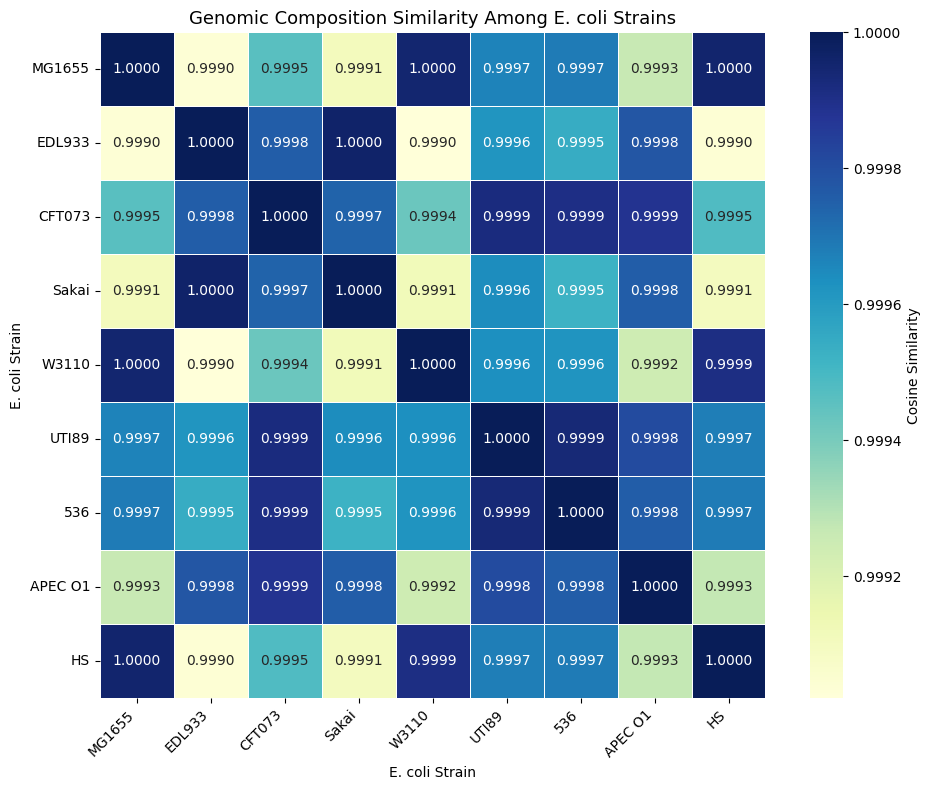

In [19]:

# STEP 18: Visualise genomic cosine similarity

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(10, 8))

sns.heatmap(
    cosine_df,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Cosine Similarity"
    }
)

plt.title(
    "Genomic Composition Similarity Among E. coli Strains",
    fontsize=13
)

plt.xlabel("E. coli Strain")
plt.ylabel("E. coli Strain")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    results_dir / "ecoli_cosine_similarity_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

# STEP 19: Identify most and least similar genome pairs

pair_results = []

strains = kmer_df["strain"].tolist()

for i in range(len(strains)):
    for j in range(i + 1, len(strains)):

        pair_results.append({
            "strain_1": strains[i],
            "strain_2": strains[j],
            "cosine_similarity": cosine_matrix[i, j]
        })

pairwise_df = pd.DataFrame(pair_results)

pairwise_df = pairwise_df.sort_values(
    "cosine_similarity",
    ascending=False
).reset_index(drop=True)

print("=== FIVE MOST SIMILAR STRAIN PAIRS ===")
display(pairwise_df.head(5))

print("\n=== FIVE LEAST SIMILAR STRAIN PAIRS ===")
display(pairwise_df.tail(5).sort_values(
    "cosine_similarity"
))

print(
    "\nMean pairwise similarity:",
    round(pairwise_df["cosine_similarity"].mean(), 6)
)

print(
    "Minimum similarity:",
    round(pairwise_df["cosine_similarity"].min(), 6)
)

print(
    "Maximum similarity:",
    round(pairwise_df["cosine_similarity"].max(), 6)
)

pairwise_df.to_csv(
    results_dir / "ecoli_pairwise_similarity.csv",
    index=False
)


=== FIVE MOST SIMILAR STRAIN PAIRS ===


,strain_1,strain_2,cosine_similarity
0,EDL933,Sakai,0.999965
1,MG1655,HS,0.999955
2,MG1655,W3110,0.999950
3,UTI89,536,0.999937
4,CFT073,UTI89,0.999920



=== FIVE LEAST SIMILAR STRAIN PAIRS ===


,strain_1,strain_2,cosine_similarity
35,EDL933,W3110,0.999021
34,MG1655,EDL933,0.999035
33,EDL933,HS,0.999037
32,Sakai,HS,0.999105
31,MG1655,Sakai,0.999108



Mean pairwise similarity: 0.99958
Minimum similarity: 0.999021
Maximum similarity: 0.999965


### Interpretation of Genomic Cosine Similarity Results

The cosine similarity analysis compared the normalised five-base k-mer frequency profiles of nine *Escherichia coli* genome assemblies.

Across the 36 unique strain pairs, the mean cosine similarity was approximately 0.999580, with values ranging from 0.999021 to 0.999965. These results indicate highly similar overall nucleotide composition among the selected genomes.

The highest similarity was observed between EDL933 and Sakai (0.999965), followed by MG1655 and HS (0.999955) and MG1655 and W3110 (0.999950). The lowest similarity was observed between EDL933 and W3110 (0.999021).

Although the genomes have broadly similar nucleotide composition, small differences in their k-mer frequency profiles allow the strains to be distinguished computationally.

These findings provide an exploratory view of genomic composition similarity. However, cosine similarity does not measure direct sequence identity, establish evolutionary ancestry, or demonstrate differences in antibiotic susceptibility.

The results will therefore be examined further using hierarchical clustering and an alternative distance metric to assess the consistency of the observed genomic relationships.

### 2.2.5 Hierarchical Clustering of E. coli Genomes

Agglomerative hierarchical clustering was selected to investigate patterns of genomic composition similarity among the nine *Escherichia coli* strains.

Cosine distance was calculated from the normalised five-base k-mer frequency profiles. Average linkage was used to progressively combine strains and groups according to their mean pairwise distances.

The resulting dendrogram provides a visual representation of the relative similarities among the genomes.

This analysis is exploratory. The dendrogram represents relationships between k-mer frequency profiles and should not be interpreted as a validated phylogenetic tree.

=== COSINE HIERARCHICAL CLUSTERING ===
Linkage matrix shape: (8, 4)


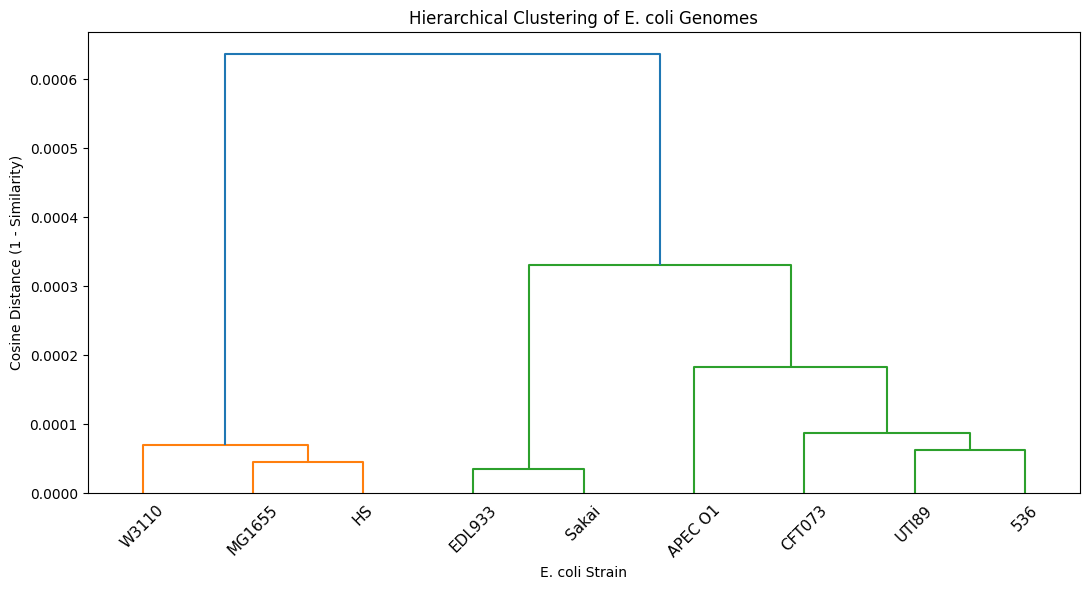

In [21]:

# STEP 20: Hierarchical clustering using cosine distance

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import numpy as np

# Convert cosine similarity to distance
cosine_distance = 1 - cosine_matrix

# Ensure exact zeros on diagonal
np.fill_diagonal(cosine_distance, 0)

# Convert to condensed distance format
condensed_cosine = squareform(
    cosine_distance,
    checks=True
)

# Average-linkage hierarchical clustering
cosine_linkage = linkage(
    condensed_cosine,
    method="average"
)

print("=== COSINE HIERARCHICAL CLUSTERING ===")
print("Linkage matrix shape:", cosine_linkage.shape)

# Plot dendrogram
plt.figure(figsize=(11, 6))

dendrogram(
    cosine_linkage,
    labels=kmer_df["strain"].tolist(),
    leaf_rotation=45,
    leaf_font_size=11
)

plt.title(
    "Hierarchical Clustering of E. coli Genomes"
)

plt.xlabel("E. coli Strain")
plt.ylabel("Cosine Distance (1 - Similarity)")

plt.tight_layout()

plt.savefig(
    results_dir / "ecoli_cosine_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 2.4 Comparative Analysis: Cosine and Euclidean Distance

To evaluate the influence of distance measurement on genomic similarity analysis, cosine distance was compared with Euclidean distance.

Both approaches were applied to the same normalised five-base k-mer frequency matrix using average-linkage hierarchical clustering.

Cosine distance measures differences in the direction of feature vectors, whereas Euclidean distance measures their absolute numerical separation.

The resulting dendrograms will be compared to determine whether the methods produce consistent groupings of the selected *E. coli* strains.

=== EUCLIDEAN HIERARCHICAL CLUSTERING ===
Euclidean distance range: 0.00028844710823727754 to 0.0015360584591690137


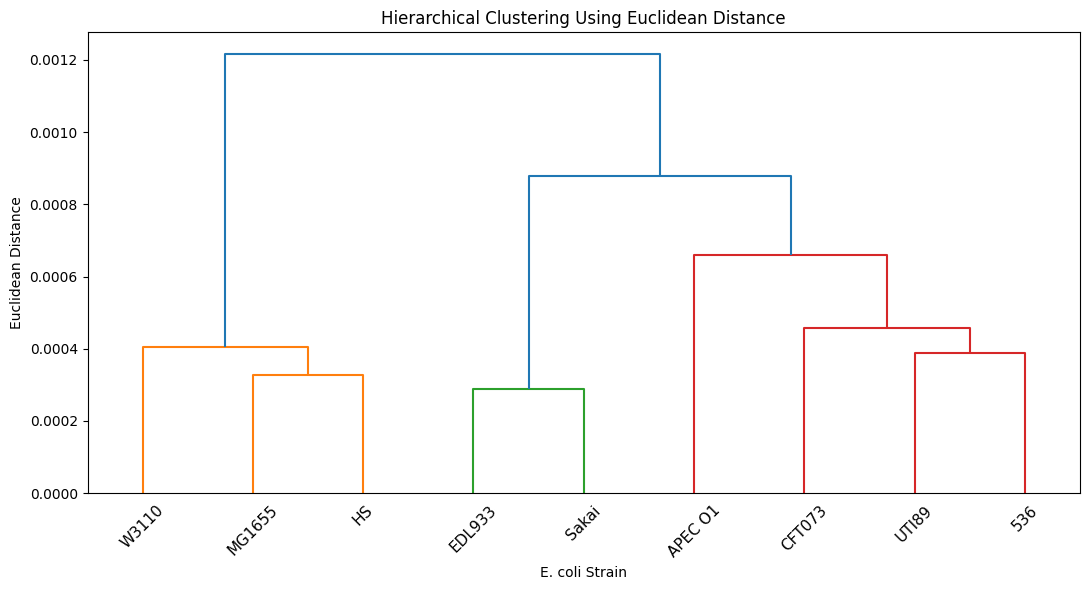

In [22]:

# STEP 21: Compare cosine and Euclidean clustering

from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Calculate Euclidean distances
euclidean_distances = pdist(
    X,
    metric="euclidean"
)

# Perform hierarchical clustering
euclidean_linkage = linkage(
    euclidean_distances,
    method="average"
)

print("=== EUCLIDEAN HIERARCHICAL CLUSTERING ===")

print(
    "Euclidean distance range:",
    euclidean_distances.min(),
    "to",
    euclidean_distances.max()
)

plt.figure(figsize=(11, 6))

dendrogram(
    euclidean_linkage,
    labels=kmer_df["strain"].tolist(),
    leaf_rotation=45,
    leaf_font_size=11
)

plt.title(
    "Hierarchical Clustering Using Euclidean Distance"
)

plt.xlabel("E. coli Strain")
plt.ylabel("Euclidean Distance")

plt.tight_layout()

plt.savefig(
    results_dir / "ecoli_euclidean_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [23]:

# STEP 22: Evaluate hierarchical clustering methods

from scipy.cluster.hierarchy import cophenet
import pandas as pd

cosine_cophenetic, _ = cophenet(
    cosine_linkage,
    condensed_cosine
)

euclidean_cophenetic, _ = cophenet(
    euclidean_linkage,
    euclidean_distances
)

comparison_df = pd.DataFrame({
    "Method": [
        "Cosine Distance",
        "Euclidean Distance"
    ],
    "Linkage": [
        "Average",
        "Average"
    ],
    "Cophenetic Correlation": [
        cosine_cophenetic,
        euclidean_cophenetic
    ]
})

print("=== CLUSTERING EVALUATION ===")

display(comparison_df.round(6))

comparison_df.to_csv(
    results_dir / "clustering_comparison.csv",
    index=False
)


=== CLUSTERING EVALUATION ===


,Method,Linkage,Cophenetic Correlation
0,Cosine Distance,Average,0.787566
1,Euclidean Distance,Average,0.863003


### 2.4.1 Comparative Analysis and Evaluation of Clustering Results

Hierarchical clustering was performed using cosine and Euclidean distances calculated from the normalised five-base k-mer frequency profiles of nine *Escherichia coli* genomes. Average linkage was applied consistently across both methods.

The two approaches produced the same visible hierarchical grouping structure. EDL933 clustered closely with Sakai, MG1655 clustered with HS and subsequently W3110, while UTI89 clustered with strain 536 and subsequently CFT073. APEC O1 joined the CFT073–UTI89–536 group at a greater distance.

The cophenetic correlation coefficient was used to evaluate how faithfully each dendrogram preserved its corresponding pairwise distance measurements. Cosine distance achieved a coefficient of 0.787566, while Euclidean distance achieved a higher coefficient of 0.863003.

These results indicate that Euclidean hierarchical clustering provided a better representation of its input distance structure for this dataset. However, the higher coefficient does not independently demonstrate greater biological accuracy, because the two methods use different distance definitions.

The agreement in the observed hierarchical groupings suggests that the broad genomic composition patterns are relatively consistent across the two methods.

The resistance-gene screening identified five resistance-associated elements in APEC O1, despite its overall k-mer composition similarity to other strains. This suggests that genome-wide composition similarity and the distribution of detected resistance-associated genes capture different aspects of genomic variation.

The dendrograms are exploratory representations of k-mer frequency relationships and should not be interpreted as definitive evolutionary phylogenies.

### 2.4.2 Evaluation of Clustering Agreement

To further evaluate the consistency of the two hierarchical clustering approaches, the dendrograms were compared using the Adjusted Rand Index (ARI).

For exploratory comparison, each dendrogram was divided into three groups. The ARI was used to measure agreement between the resulting strain assignments, accounting for agreement expected by chance.

Additionally, the cophenetic distances produced by the two methods were compared using Pearson correlation to assess their overall structural agreement.

These measurements evaluate consistency between clustering methods rather than the biological correctness of the identified groups. The choice of three groups is exploratory and does not represent a known number of biological lineages.

In [24]:

# STEP 23: Compare clustering agreement

from scipy.cluster.hierarchy import cut_tree, cophenet
from sklearn.metrics import adjusted_rand_score
from scipy.stats import pearsonr
import pandas as pd

# Exploratory comparison using three clusters
n_clusters = 3

cosine_labels = cut_tree(
    cosine_linkage,
    n_clusters=n_clusters
).flatten()

euclidean_labels = cut_tree(
    euclidean_linkage,
    n_clusters=n_clusters
).flatten()

# Compare cluster assignments
ari_score = adjusted_rand_score(
    cosine_labels,
    euclidean_labels
)

# Extract cophenetic distances
_, cosine_coph_distances = cophenet(
    cosine_linkage,
    condensed_cosine
)

_, euclidean_coph_distances = cophenet(
    euclidean_linkage,
    euclidean_distances
)

# Compare dendrogram distance structures
coph_correlation, coph_pvalue = pearsonr(
    cosine_coph_distances,
    euclidean_coph_distances
)

# Display strain assignments
cluster_assignments_df = pd.DataFrame({
    "strain": kmer_df["strain"].values,
    "cosine_cluster": cosine_labels + 1,
    "euclidean_cluster": euclidean_labels + 1
})

print("=== CLUSTER ASSIGNMENTS ===")
display(cluster_assignments_df)

print("\n=== COMPARATIVE EVALUATION ===")

print("Number of clusters:", n_clusters)
print("Adjusted Rand Index:", round(ari_score, 6))
print(
    "Cophenetic distance correlation:",
    round(coph_correlation, 6)
)

# Save results
cluster_assignments_df.to_csv(
    results_dir / "cluster_assignments.csv",
    index=False
)


=== CLUSTER ASSIGNMENTS ===


,strain,cosine_cluster,euclidean_cluster
0,MG1655,1,1
1,EDL933,2,2
2,CFT073,3,3
3,Sakai,2,2
4,W3110,1,1
5,UTI89,3,3
6,536,3,3
7,APEC O1,3,3
8,HS,1,1



=== COMPARATIVE EVALUATION ===
Number of clusters: 3
Adjusted Rand Index: 1.0
Cophenetic distance correlation: 0.989512


=== CLUSTERING AGREEMENT ACROSS CLUSTER COUNTS ===


,number_of_clusters,adjusted_rand_index
0,2,1.0
1,3,1.0
2,4,1.0
3,5,1.0
4,6,1.0
5,7,1.0
6,8,1.0


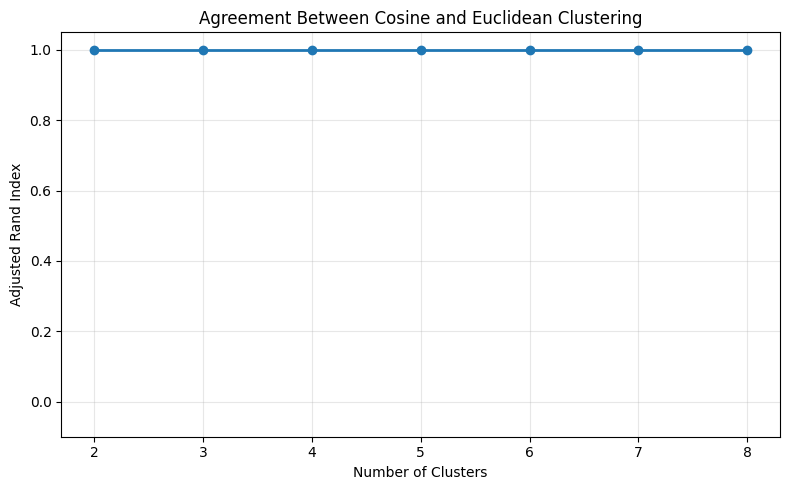

In [25]:

# STEP 24: Evaluate clustering agreement
# across different numbers of clusters

from scipy.cluster.hierarchy import cut_tree
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import matplotlib.pyplot as plt

stability_results = []

for n in range(2, 9):

    cosine_groups = cut_tree(
        cosine_linkage,
        n_clusters=n
    ).flatten()

    euclidean_groups = cut_tree(
        euclidean_linkage,
        n_clusters=n
    ).flatten()

    ari = adjusted_rand_score(
        cosine_groups,
        euclidean_groups
    )

    stability_results.append({
        "number_of_clusters": n,
        "adjusted_rand_index": ari
    })

stability_df = pd.DataFrame(stability_results)

print("=== CLUSTERING AGREEMENT ACROSS CLUSTER COUNTS ===")

display(stability_df.round(6))

plt.figure(figsize=(8, 5))

plt.plot(
    stability_df["number_of_clusters"],
    stability_df["adjusted_rand_index"],
    marker="o",
    linewidth=2
)

plt.title(
    "Agreement Between Cosine and Euclidean Clustering"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Adjusted Rand Index")

plt.ylim(-0.1, 1.05)
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    results_dir / "clustering_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

stability_df.to_csv(
    results_dir / "clustering_stability.csv",
    index=False
)


### 2.4.4 Evaluation of Clustering Agreement Across Different Cluster Counts

The agreement between cosine and Euclidean hierarchical clustering was further evaluated by varying the number of clusters from two to eight.

For each cluster count, the Adjusted Rand Index (ARI) was calculated to compare the strain assignments produced by the two methods.

The analysis returned an ARI of 1.000000 for all seven tested cluster counts, indicating identical group memberships between the two methods throughout the evaluated range.

These findings demonstrate that the observed hierarchical groupings are consistent across cosine and Euclidean distance measurements for the selected dataset.

Combined with the cophenetic distance correlation of 0.989512, the results indicate very strong structural agreement between the two dendrograms.

Although Euclidean distance achieved a higher individual cophenetic correlation coefficient (0.863003) than cosine distance (0.787566), both methods produced the same group memberships.

Therefore, neither method demonstrated an advantage in terms of cluster assignment consistency. Euclidean distance demonstrated better preservation of its original pairwise distances, while both approaches identified the same genomic composition groupings.

These findings support the reproducibility of the observed groupings across the two selected distance measures. However, they do not establish phylogenetic accuracy or demonstrate stability under changes in genome sampling, k-mer length or sequence quality.